# 04 · Self-distillation: train agents on the base model's best answers

Runtime > Change runtime type > **T4 GPU**.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!nvidia-smi

Mounted at /content/drive
Wed Nov 25 17:17:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

In [18]:
import getpass, os
GITHUB_USER = 'natitedros'
REPO = 'CMVA-context-based-aggregation'
token = getpass.getpass('GitHub token (leave blank if repo is public): ')
auth = f'{token}@' if token else ''
%cd /content
!rm -rf /content/repo
!git clone -q https://{auth}github.com/{GITHUB_USER}/{REPO}.git /content/repo
%cd /content/repo
del token, auth

GitHub token (leave blank if repo is public): ··········
/content
/content/repo


In [3]:
!pip install -q -r requirements.txt
!pip uninstall -y -q torchao

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import os
os.environ['PROJECT_ROOT'] = '/content/drive/MyDrive/NLP-Final'
os.environ['SCRATCH_DIR'] = '/content/scratch'
DISTILLED = os.environ['PROJECT_ROOT'] + '/data/agent_data_distilled'

### 1. Smoke test: 32 questions
Checks the whole pipeline in a few minutes. Delete its outputs afterwards (next cell).

In [7]:
!python src/distill_data.py --n_questions 32 --chunk 16

Loaded 113,828 rows. Columns: ['chatbot', 'Q', 'A', 'rot', 'moral', 'moral-vector', 'A_agrees', 'rot-agree', 'violation-severity', 'worker_answer', 'comments', 'QA', 'split']
Dropping 2 malformed rows (non-numeric A_agrees).
A_agrees values: {2: 66261, 0: 23166, 1: 18766}
split values: {'train': 86529, 'dev': 10842, 'test': 10817}
Sample 'moral' values: ['loyalty', 'care|fairness', 'care', 'authority|sanctity', 'authority']
Ignoring 5 rows with an unrecognised split value.
Using MIC's own train/dev/test split.
32 train questions x 5 answers each
All 2 chunks already generated
Scores already computed

160 of 160 answers usable; 16% finished within 128 tokens

value       average answer  random pick  selected    gap
care                 0.838        0.830     0.928 +0.098
fairness             0.635        0.650     0.746 +0.096
loyalty              0.684        0.685     0.775 +0.090
authority            0.777        0.797     0.886 +0.089
sanctity             0.725        0.739     0.80

In [8]:
# Remove the smoke-test outputs before the real run
!rm -rf "$PROJECT_ROOT/data/distill" "$PROJECT_ROOT/data/agent_data_distilled"

### 2. Real run: 2,000 questions × 5 answers
Resumable: if Colab disconnects, rerun the setup cells and this cell, and it continues from the last saved chunk.

In [9]:
!python src/distill_data.py

Loaded 113,828 rows. Columns: ['chatbot', 'Q', 'A', 'rot', 'moral', 'moral-vector', 'A_agrees', 'rot-agree', 'violation-severity', 'worker_answer', 'comments', 'QA', 'split']
Dropping 2 malformed rows (non-numeric A_agrees).
A_agrees values: {2: 66261, 0: 23166, 1: 18766}
split values: {'train': 86529, 'dev': 10842, 'test': 10817}
Sample 'moral' values: ['loyalty', 'care|fairness', 'care', 'authority|sanctity', 'authority']
Ignoring 5 rows with an unrecognised split value.
Using MIC's own train/dev/test split.
2000 train questions x 5 answers each
Loading weights: 100% 290/290 [00:04<00:00, 69.19it/s]
chunk 1/10: 1000 answers saved
chunk 2/10: 1000 answers saved
chunk 3/10: 1000 answers saved
chunk 4/10: 1000 answers saved
chunk 5/10: 1000 answers saved
chunk 6/10: 1000 answers saved
chunk 7/10: 1000 answers saved
chunk 8/10: 1000 answers saved
chunk 9/10: 1000 answers saved
chunk 10/10: 1000 answers saved
scoring 10,000 answers for care
Loading weights: 100% 201/201 [00:00<00:00, 688.

### 3. The gap check
`gap_vs_random` should be clearly positive for every value, and `mean_selected` for care should be well above 0.87.

In [10]:
import json
print(json.dumps(json.load(open(DISTILLED + '/stats.json')), indent=2))

{
  "settings": {
    "n_questions": 2000,
    "k": 5,
    "temperature": 0.8,
    "top_p": 0.95,
    "max_new_tokens": 128,
    "batch": 16,
    "chunk": 200
  },
  "answers_total": 10000,
  "answers_usable": 10000,
  "pct_finished": 0.186,
  "questions_usable": 2000,
  "care": {
    "mean_all_answers": 0.8665,
    "mean_random_pick": 0.867,
    "mean_selected": 0.9287,
    "examples": 2000,
    "gap_vs_random": 0.0617
  },
  "fairness": {
    "mean_all_answers": 0.6496,
    "mean_random_pick": 0.6508,
    "mean_selected": 0.7558,
    "examples": 2000,
    "gap_vs_random": 0.105
  },
  "loyalty": {
    "mean_all_answers": 0.7286,
    "mean_random_pick": 0.7291,
    "mean_selected": 0.8121,
    "examples": 2000,
    "gap_vs_random": 0.083
  },
  "authority": {
    "mean_all_answers": 0.7824,
    "mean_random_pick": 0.7834,
    "mean_selected": 0.8716,
    "examples": 2000,
    "gap_vs_random": 0.0882
  },
  "sanctity": {
    "mean_all_answers": 0.7466,
    "mean_random_pick": 0.7466,
 

### 4. Train the care agent in both arms, plus the control

In [11]:
!python src/train_agent.py --mode lora --value care --data_dir "$PROJECT_ROOT/data/agent_data_distilled" --tag _sd
!python src/train_agent.py --mode full --value care --data_dir "$PROJECT_ROOT/data/agent_data_distilled" --tag _sd
!python src/train_agent.py --mode lora --value control --data_dir "$PROJECT_ROOT/data/agent_data_distilled" --tag _sd

2000 training examples for lora_care_sd
Loading weights: 100% 290/290 [00:03<00:00, 83.46it/s] 
Trainable parameters: 8,798,208 of 502,830,976 (1.75%)
{'loss': '1.161', 'grad_norm': '1.796', 'learning_rate': '0.0001992', 'epoch': '0.08'}
{'loss': '1.158', 'grad_norm': '0.9752', 'learning_rate': '0.0001909', 'epoch': '0.16'}
{'loss': '1.124', 'grad_norm': '1.102', 'learning_rate': '0.0001826', 'epoch': '0.24'}
{'loss': '1.109', 'grad_norm': '0.964', 'learning_rate': '0.0001744', 'epoch': '0.32'}
{'loss': '1.114', 'grad_norm': '0.97', 'learning_rate': '0.0001661', 'epoch': '0.4'}
{'loss': '1.082', 'grad_norm': '0.9124', 'learning_rate': '0.0001579', 'epoch': '0.48'}
{'loss': '1.103', 'grad_norm': '0.9355', 'learning_rate': '0.0001496', 'epoch': '0.56'}
{'loss': '1.093', 'grad_norm': '0.9757', 'learning_rate': '0.0001413', 'epoch': '0.64'}
{'loss': '1.098', 'grad_norm': '0.9669', 'learning_rate': '0.0001331', 'epoch': '0.72'}
{'loss': '1.075', 'grad_norm': '0.8375', 'learning_rate': '0.00

### 5. Score all three on the 500 held-out questions

In [12]:
A = os.environ['PROJECT_ROOT'] + '/models/agents'
!python src/generate_and_score.py --tag lora_care_sd --adapter "{A}/lora_care_sd" --n 500
!python src/generate_and_score.py --tag full_care_sd --model "{A}/full_care_sd" --n 500
!python src/generate_and_score.py --tag lora_control_sd --adapter "{A}/lora_control_sd" --n 500

Generating 500 answers with /content/drive/MyDrive/NLP-Final/models/agents/lora_care_sd
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100% 290/290 [00:00<00:00, 413.84it/s]
  generated 16/500
  generated 32/500
  generated 48/500
  generated 64/500
  generated 80/500
  generated 96/500
  generated 112/500
  generated 128/500
  generated 144/500
  generated 160/500
  generated 176/500
  generated 192/500
  generated 208/500
  generated 224/500
  generated 240/500
  generated 256/500
  generated 272/500
  generated 288/500
  generated 304/500
  generated 320/500
  generated 336/500
  generated 352/500
  generated 368/500
  generated 384/500
  generated 400/500
  generated 416/500
  generated 432/500
  generated 448/500
  generated 464/500
  generated 480/500
  generated 496/500
  generated 500/500
Loading weights: 100% 201/201 [00:00<00:00, 593.84it/s]
care       expected reward 0.889
Loading weights: 100% 201/201 [00:00<00:00, 932.84it/s]
fairness   e

### 6. Compare with the base model

In [13]:
import pandas as pd
R = os.environ['PROJECT_ROOT'] + '/results'
VALUES = ['care', 'fairness', 'loyalty', 'authority', 'sanctity']
tags = ['pt', 'full_care_sd', 'lora_care_sd', 'lora_control_sd']
table = pd.DataFrame({t: {v: json.load(open(f'{R}/alignment_{t}.json'))[v]['expected_reward'] for v in VALUES} for t in tags})
table

,pt,full_care_sd,lora_care_sd,lora_control_sd
care,0.8705,0.8977,0.8894,0.8673
fairness,0.6412,0.6674,0.6611,0.6384
loyalty,0.7297,0.7520,0.7543,0.7287
authority,0.7744,0.7959,0.7956,0.7721
sanctity,0.7404,0.7527,0.7489,0.7367


Checking if the difference is real or noise

In [14]:
import numpy as np, pandas as pd
R = os.environ['PROJECT_ROOT'] + '/results'
load = lambda t: pd.read_csv(f'{R}/generations_{t}.csv')
rng = np.random.default_rng(0)

def compare(a, b, col='p_care'):
    d = (load(a)[col] - load(b)[col]).to_numpy()
    boots = [rng.choice(d, len(d)).mean() for _ in range(2000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f'{a:16s} − {b:16s} {d.mean():+.3f}   95% CI {lo:+.3f} to {hi:+.3f}')

for a, b in [('full_care_sd', 'pt'), ('lora_care_sd', 'pt'), ('lora_control_sd', 'pt'),
             ('lora_care_sd', 'lora_control_sd'), ('full_care_sd', 'lora_care_sd')]:
    compare(a, b)

full_care_sd     − pt               +0.027   95% CI +0.017 to +0.037
lora_care_sd     − pt               +0.019   95% CI +0.010 to +0.028
lora_control_sd  − pt               -0.003   95% CI -0.014 to +0.008
lora_care_sd     − lora_control_sd  +0.022   95% CI +0.014 to +0.030
full_care_sd     − lora_care_sd     +0.008   95% CI +0.001 to +0.016


In [15]:
D = os.environ['PROJECT_ROOT'] + '/data/agent_data_distilled'
A = os.environ['PROJECT_ROOT'] + '/models/agents'
for v in ['fairness', 'loyalty', 'authority', 'sanctity']:
    for mode in ['lora', 'full']:
        !python src/train_agent.py --mode {mode} --value {v} --data_dir "{D}" --tag _sd
    !python src/generate_and_score.py --tag lora_{v}_sd --adapter "{A}/lora_{v}_sd" --n 500
    !python src/generate_and_score.py --tag full_{v}_sd --model "{A}/full_{v}_sd" --n 500

2000 training examples for lora_fairness_sd
Loading weights: 100% 290/290 [00:01<00:00, 157.88it/s]
Trainable parameters: 8,798,208 of 502,830,976 (1.75%)
{'loss': '1.16', 'grad_norm': '1.6', 'learning_rate': '0.0001992', 'epoch': '0.08'}
{'loss': '1.134', 'grad_norm': '1.005', 'learning_rate': '0.0001909', 'epoch': '0.16'}
{'loss': '1.149', 'grad_norm': '1.034', 'learning_rate': '0.0001826', 'epoch': '0.24'}
{'loss': '1.089', 'grad_norm': '0.9614', 'learning_rate': '0.0001744', 'epoch': '0.32'}
{'loss': '1.107', 'grad_norm': '0.9817', 'learning_rate': '0.0001661', 'epoch': '0.4'}
{'loss': '1.085', 'grad_norm': '0.9576', 'learning_rate': '0.0001579', 'epoch': '0.48'}
{'loss': '1.1', 'grad_norm': '0.9171', 'learning_rate': '0.0001496', 'epoch': '0.56'}
{'loss': '1.103', 'grad_norm': '0.8929', 'learning_rate': '0.0001413', 'epoch': '0.64'}
{'loss': '1.086', 'grad_norm': '0.9442', 'learning_rate': '0.0001331', 'epoch': '0.72'}
{'loss': '1.078', 'grad_norm': '0.911', 'learning_rate': '0.00

Check for each training successful execution

In [16]:
import os
R = os.environ['PROJECT_ROOT'] + '/results'
for v in ['fairness', 'loyalty', 'authority', 'sanctity']:
    for m in ['lora', 'full']:
        name = f'{m}_{v}_sd'
        trained = os.path.exists(f'{R}/agent_{name}.json')
        scored = os.path.exists(f'{R}/alignment_{name}.json')
        print(f'{name:18s} trained: {trained}   scored: {scored}')

lora_fairness_sd   trained: True   scored: True
full_fairness_sd   trained: True   scored: True
lora_loyalty_sd    trained: True   scored: True
full_loyalty_sd    trained: True   scored: True
lora_authority_sd  trained: True   scored: True
full_authority_sd  trained: True   scored: True
lora_sanctity_sd   trained: True   scored: True
full_sanctity_sd   trained: True   scored: True


Summary

In [17]:
import json, os
import numpy as np, pandas as pd
R = os.environ['PROJECT_ROOT'] + '/results'
VALUES = ['care', 'fairness', 'loyalty', 'authority', 'sanctity']
align = lambda t: json.load(open(f'{R}/alignment_{t}.json'))
gens = lambda t: pd.read_csv(f'{R}/generations_{t}.csv')

# 1. Five-by-five tables: each column is a model, each row is the classifier that scored it
for arm in ['full', 'lora']:
    cols = {'base': 'pt', 'control': 'lora_control_sd', **{f'{v}_agent': f'{arm}_{v}_sd' for v in VALUES}}
    t = pd.DataFrame({c: {v: align(tag)[v]['expected_reward'] for v in VALUES} for c, tag in cols.items()})
    print(f'\n=== {arm.upper()} arm: expected reward ===')
    print(t.round(3).to_string())

# 2. Each agent on its own value, question by question, with 95% bootstrap intervals
rng = np.random.default_rng(0)
def ci(a, b, col):
    d = (gens(a)[col] - gens(b)[col]).to_numpy()
    boots = [rng.choice(d, len(d)).mean() for _ in range(2000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return f'{d.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]'
rows = []
for v in VALUES:
    c = f'p_{v}'
    rows.append({'value': v,
                 'full - base': ci(f'full_{v}_sd', 'pt', c),
                 'lora - base': ci(f'lora_{v}_sd', 'pt', c),
                 'lora - control': ci(f'lora_{v}_sd', 'lora_control_sd', c),
                 'full - lora': ci(f'full_{v}_sd', f'lora_{v}_sd', c)})
print('\n=== Own-value differences, mean [95% CI] ===')
print(pd.DataFrame(rows).to_string(index=False))

# 3. Training cost of every agent
keys = ['trainable_params', 'peak_train_gpu_mb', 'train_seconds', 'saved_size_mb', 'avg_train_loss']
eff = {f'{m}_{v}': {k: json.load(open(f'{R}/agent_{m}_{v}_sd.json')).get(k) for k in keys}
       for v in VALUES for m in ['full', 'lora']}
eff['lora_control'] = {k: json.load(open(f'{R}/agent_lora_control_sd.json')).get(k) for k in keys}
print('\n=== Training cost ===')
print(pd.DataFrame(eff).T.to_string())


=== FULL arm: expected reward ===
            base  control  care_agent  fairness_agent  loyalty_agent  authority_agent  sanctity_agent
care       0.870    0.867       0.898           0.880          0.885            0.889           0.890
fairness   0.641    0.638       0.667           0.690          0.662            0.670           0.670
loyalty    0.730    0.729       0.752           0.750          0.771            0.761           0.761
authority  0.774    0.772       0.796           0.796          0.799            0.816           0.811
sanctity   0.740    0.737       0.753           0.753          0.754            0.761           0.780

=== LORA arm: expected reward ===
            base  control  care_agent  fairness_agent  loyalty_agent  authority_agent  sanctity_agent
care       0.870    0.867       0.889           0.885          0.881            0.887           0.883
fairness   0.641    0.638       0.661           0.680          0.651            0.666           0.662
loyalty    0

Evaluations

saved /content/drive/MyDrive/NLP-Final/results/figures/1_own_value_gain.png
saved /content/drive/MyDrive/NLP-Final/results/figures/2_value_specificity.png
saved /content/drive/MyDrive/NLP-Final/results/figures/3_lora_cost_vs_gain.png


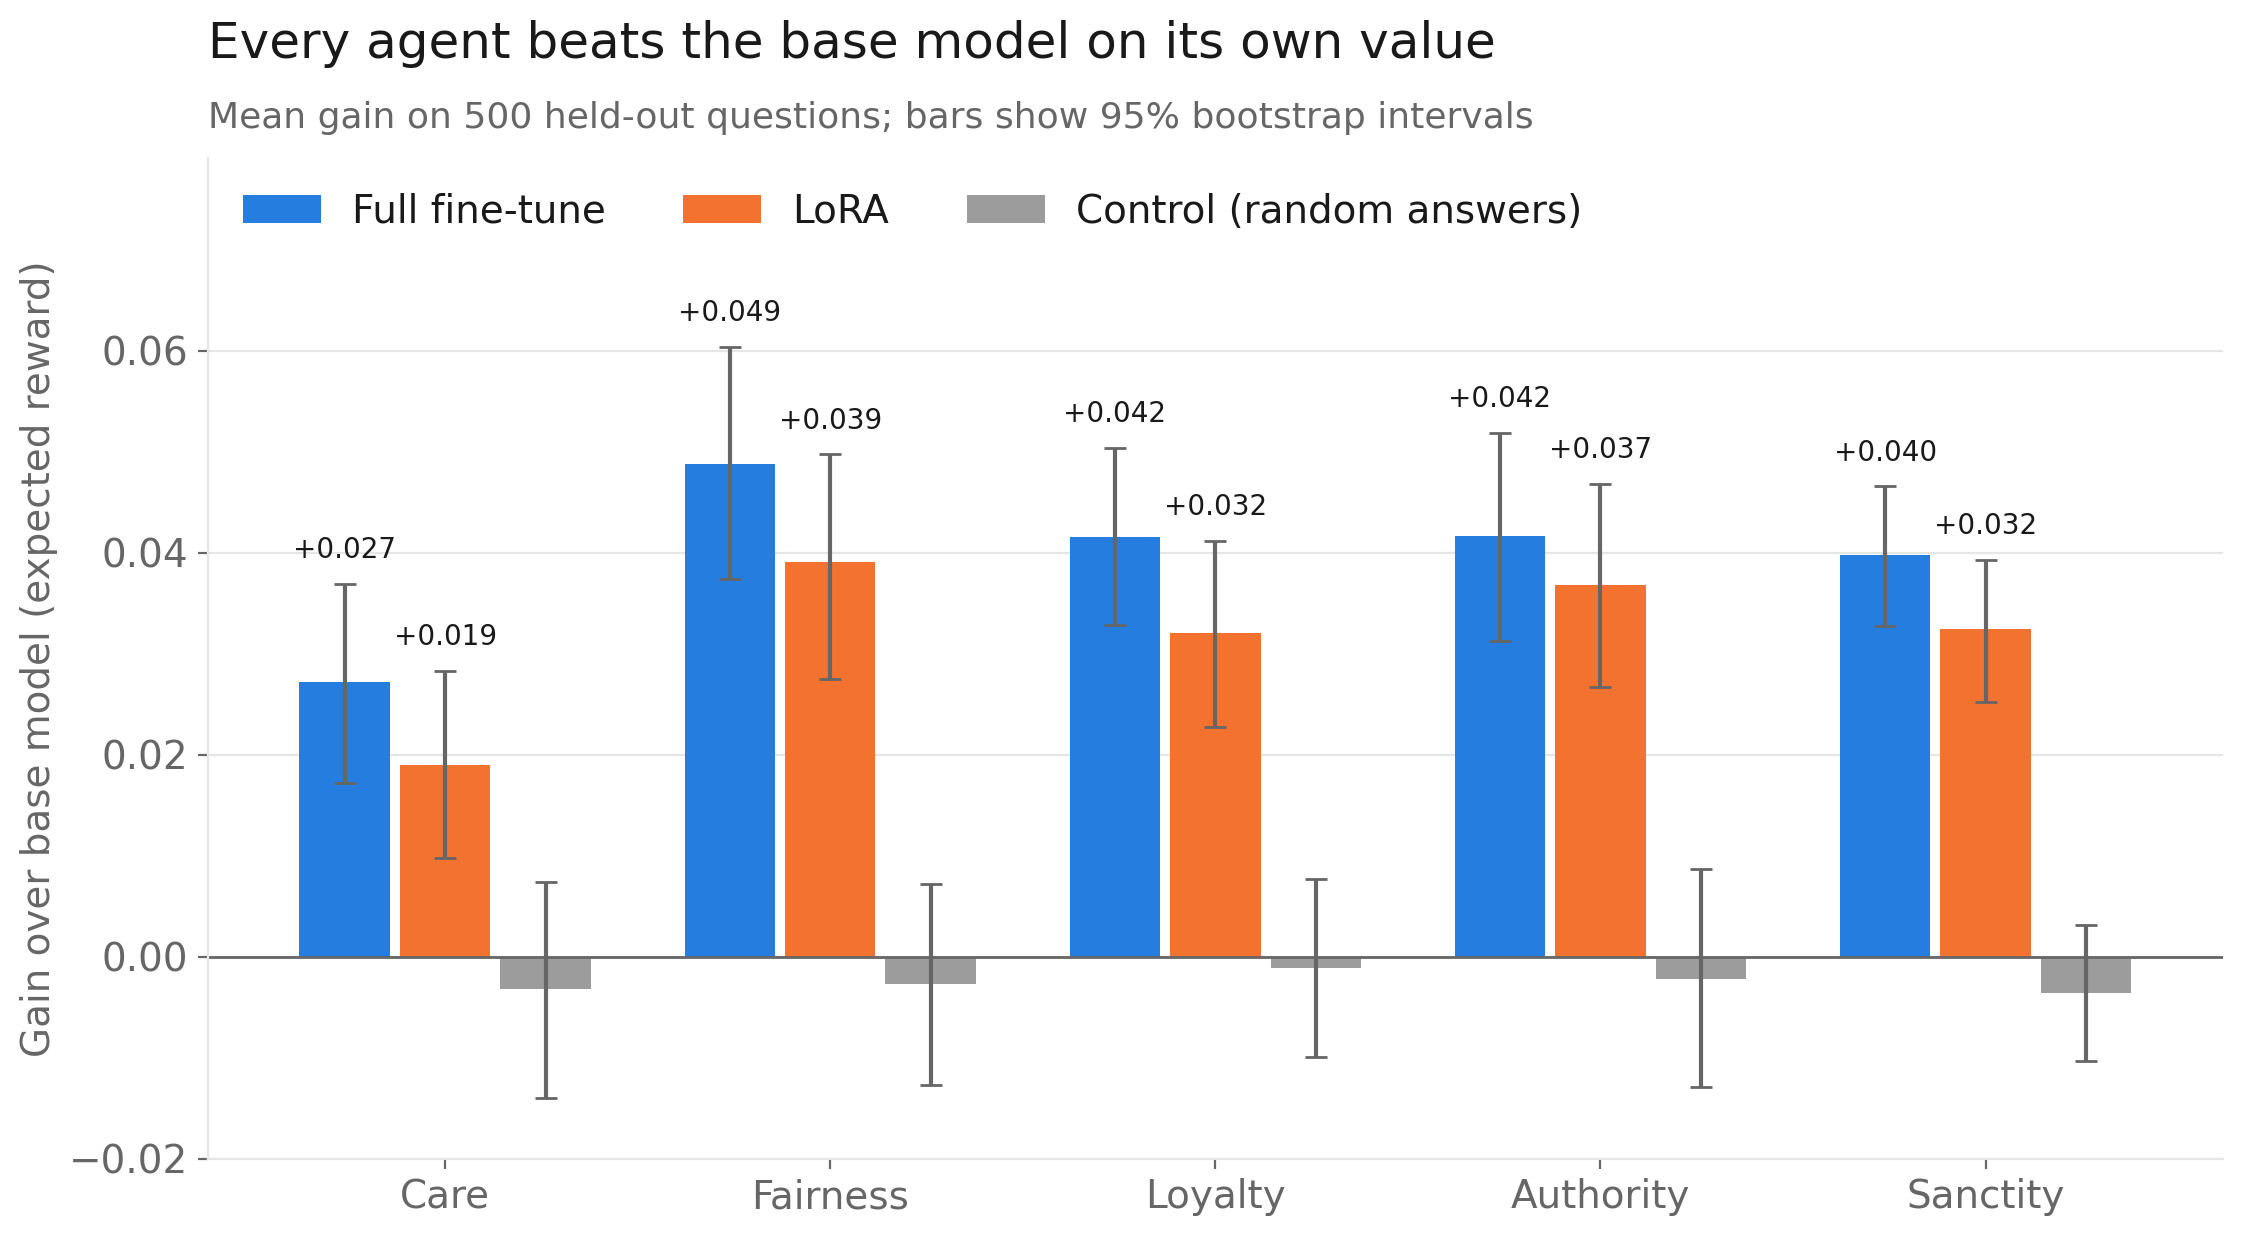

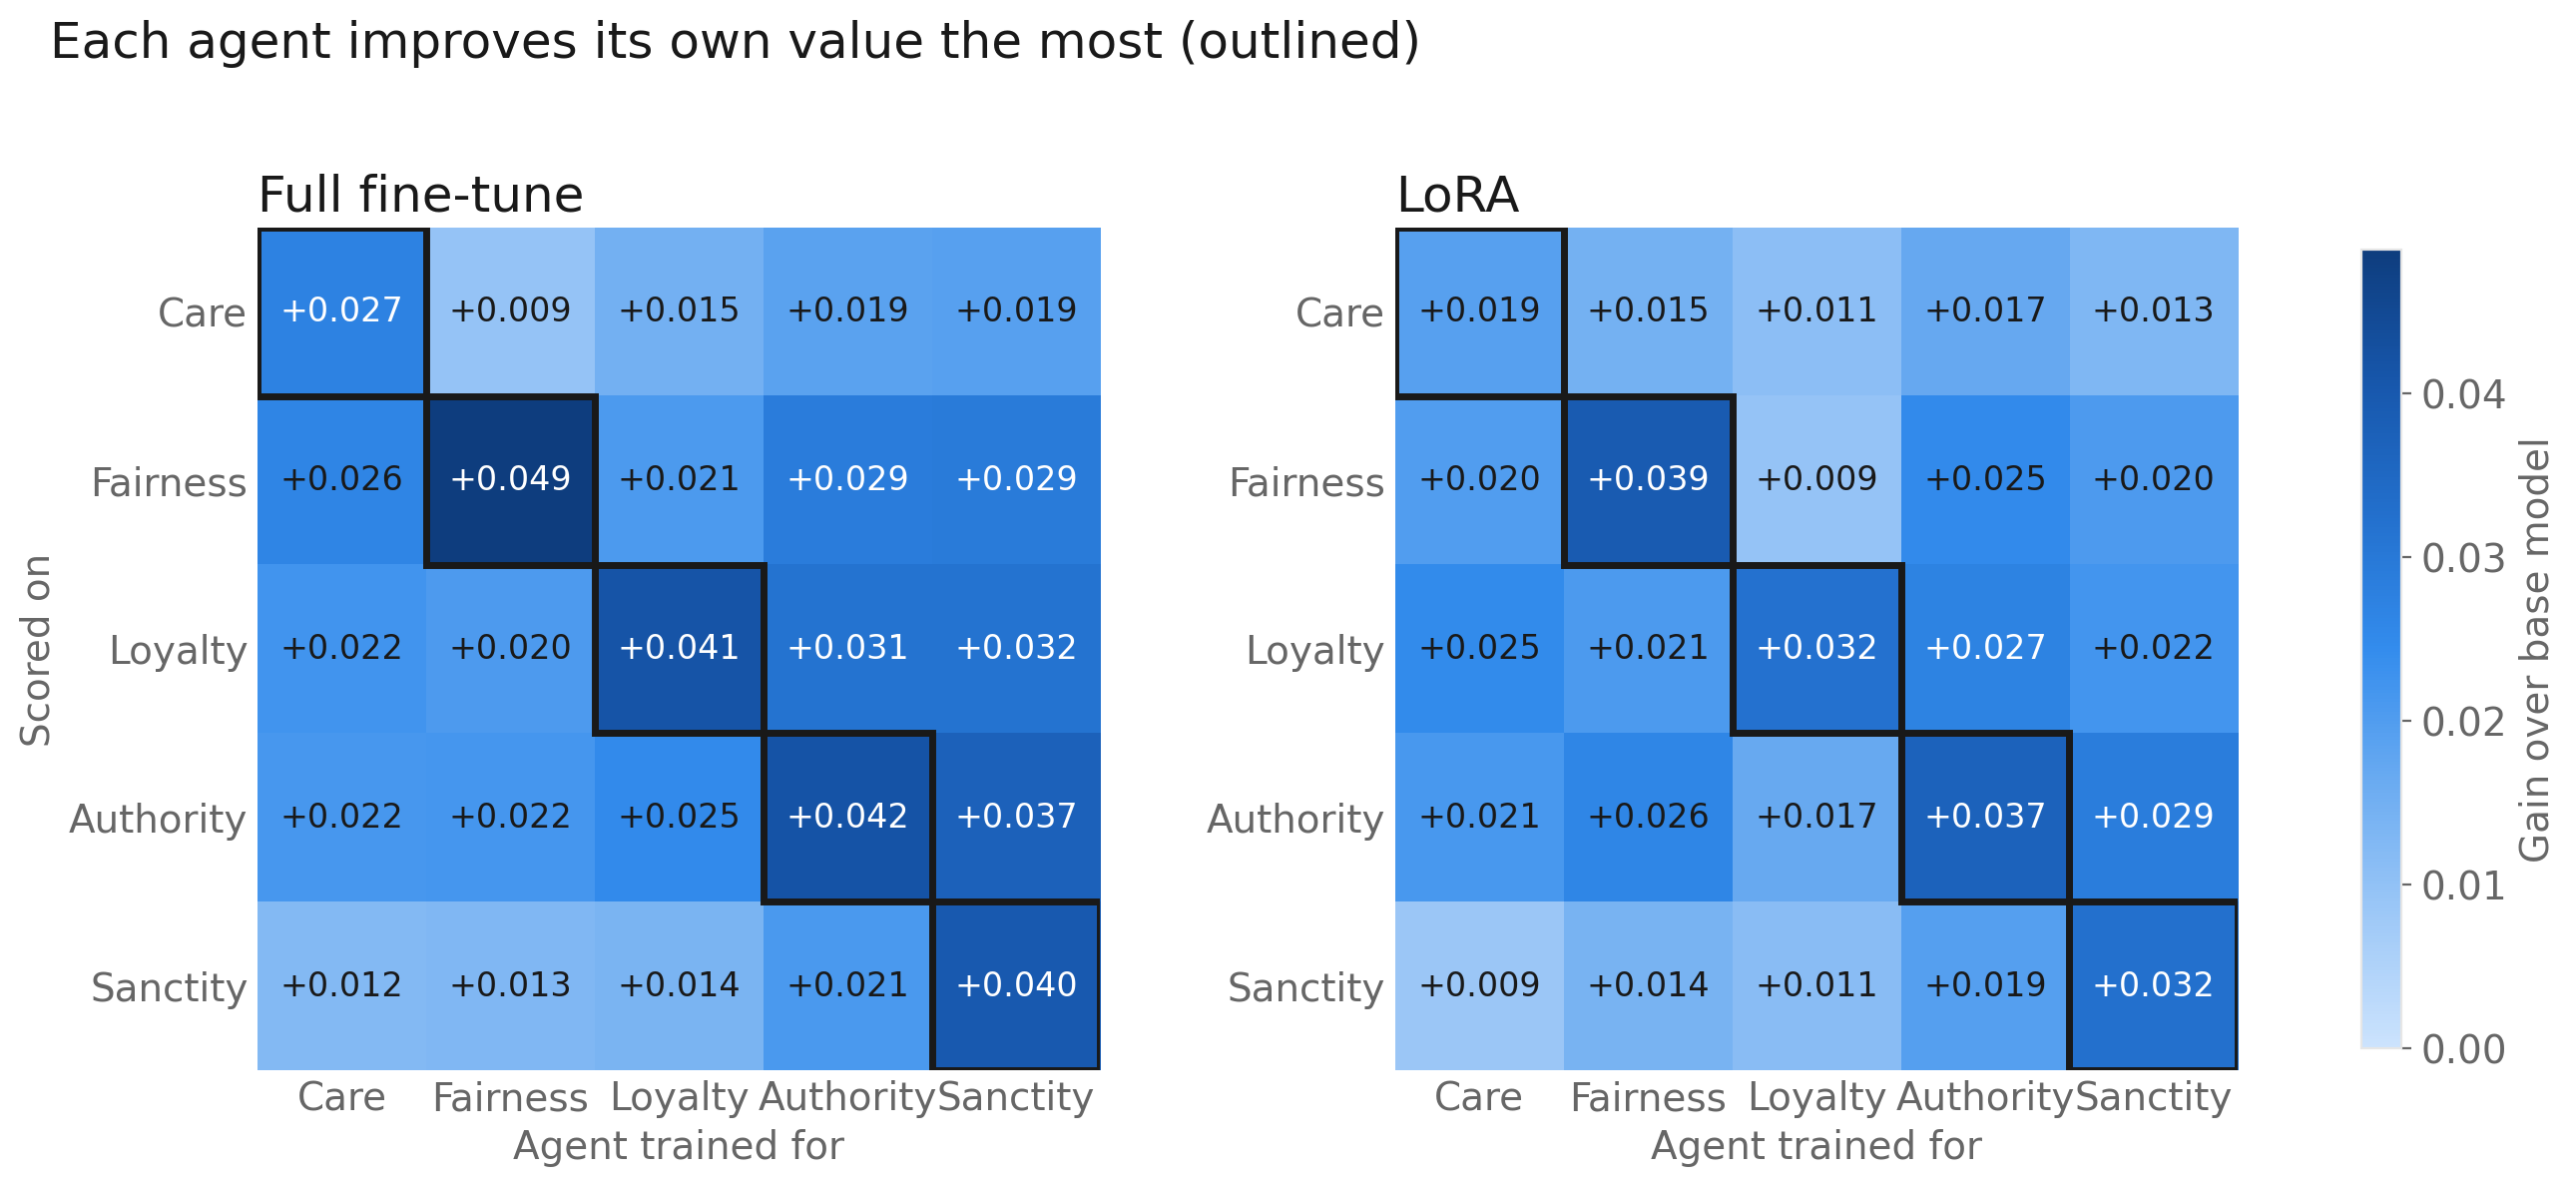

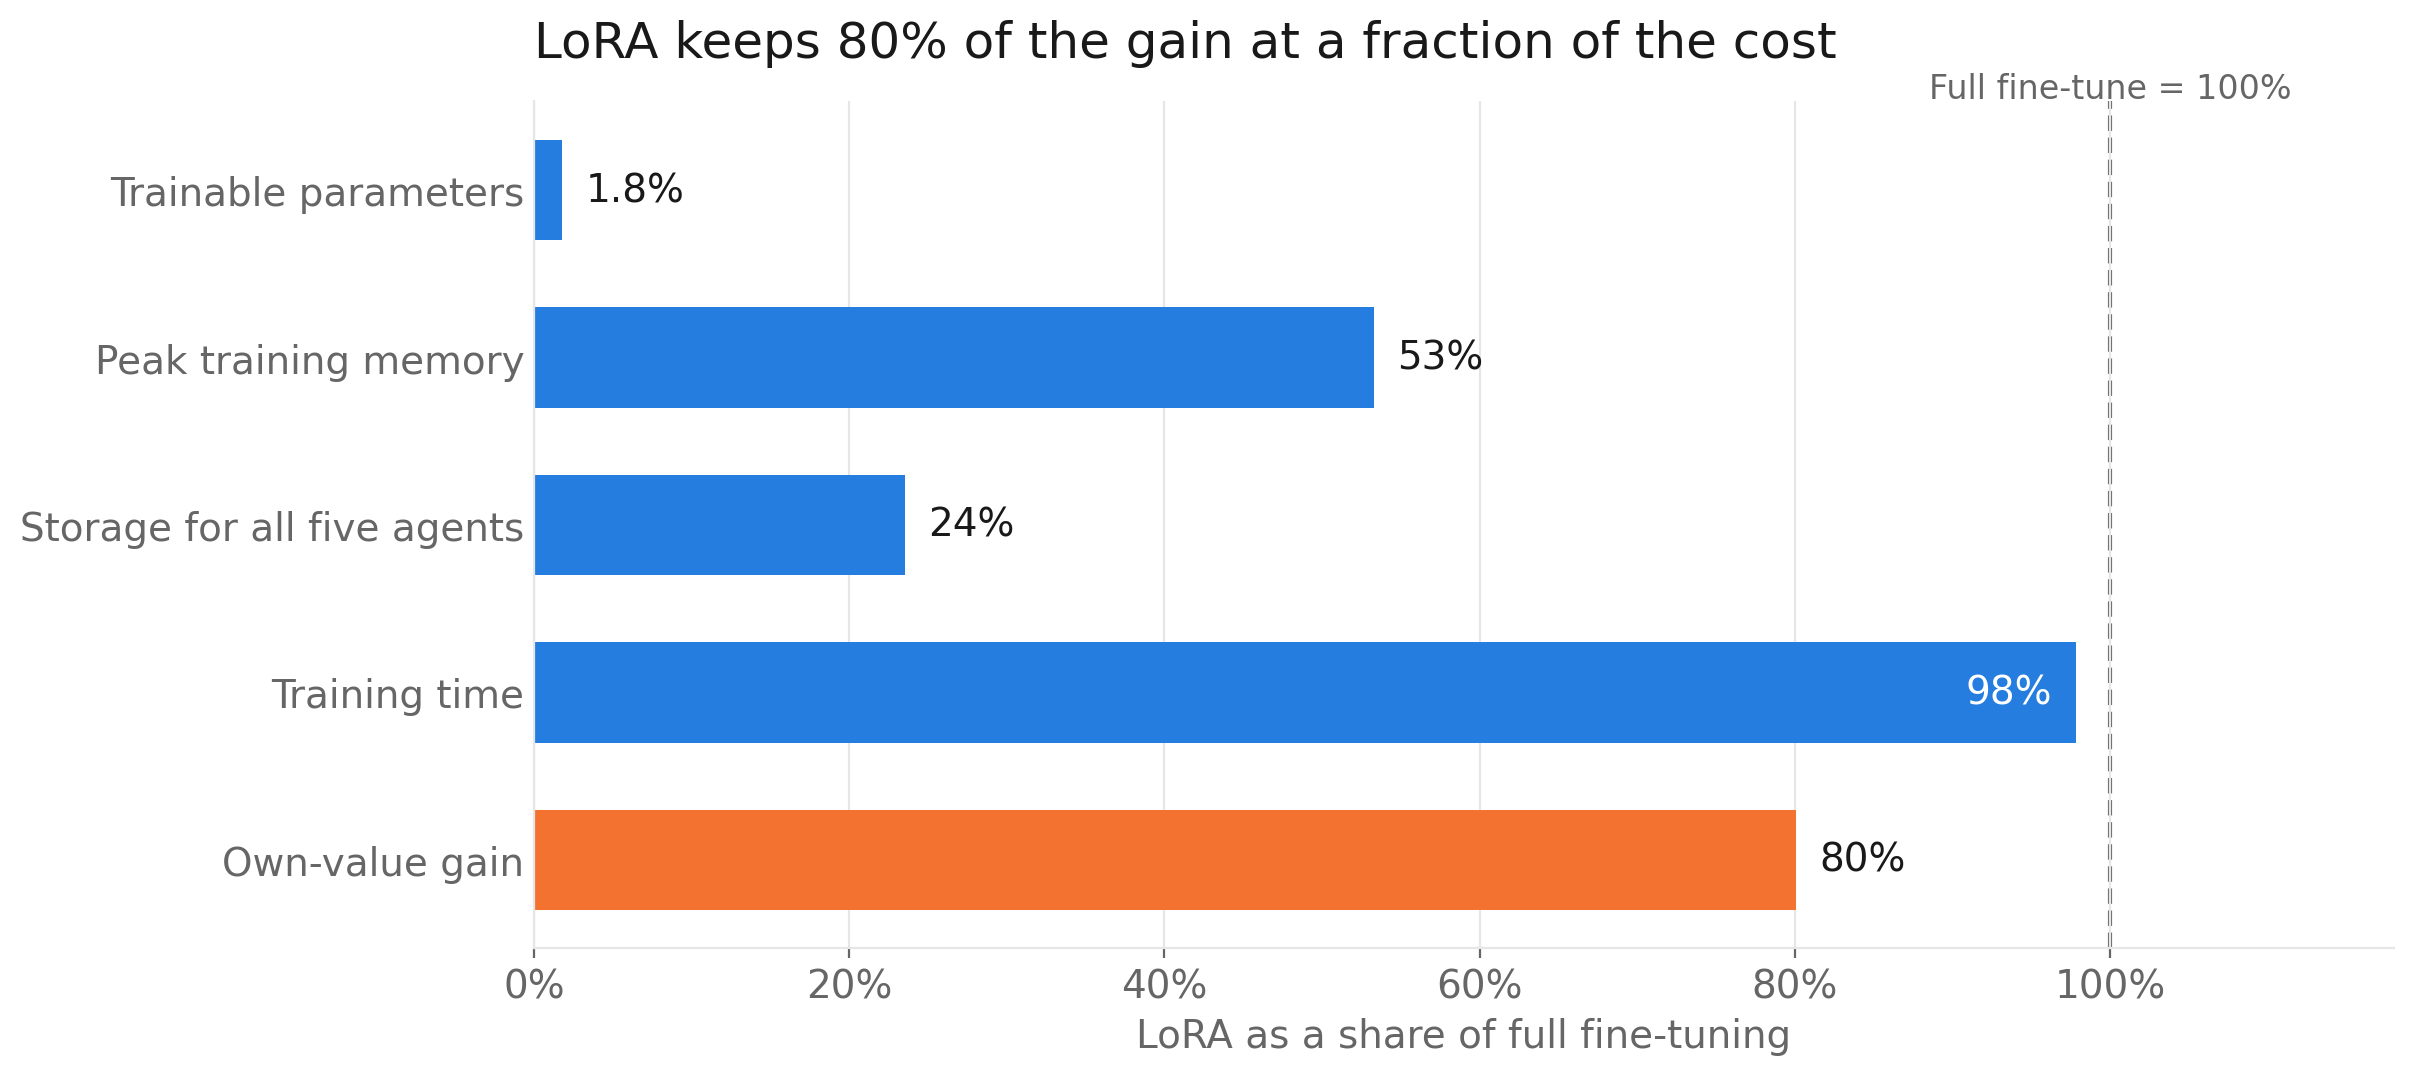

In [19]:
!python src/plot_agents.py

from IPython.display import Image, display
F = os.environ['PROJECT_ROOT'] + '/results/figures'
for name in ['1_own_value_gain', '2_value_specificity', '3_lora_cost_vs_gain']:
    display(Image(f'{F}/{name}.png'))